# Лабораторна 2. Від сирих даних до нейромережі

У цій лабораторній роботі ви пройдете повний цикл роботи з табличним датасетом для задачі регресії — від завантаження до порівняння моделей:

- дослідницький аналіз даних (EDA): загальний огляд, гістограми, кореляції;
- обробка пропусків і викидів;
- інженерія ознак;
- baseline: множинна лінійна регресія;
- нейромережа — підбір архітектури, функцій активації, оптимізатора власними експериментами;
- чесне порівняння моделей на test за метриками регресії (MSE, RMSE, MAE, R²).

Демо-ноутбук з лекції 3-4 — основа, звертайтесь до нього як до довідника, коли щось незрозуміло.

## 0. Опрацюйте демо-ноутбук з лекції
Прогляньте пояснення ноутбуку і запустіть всі клітинки демо-ноутбуку (крім тих секцій, в яких вказано, що їх запускати не можна).
Після цього дайте тут відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

### 0.1 Мої відповіді:
1. Метод kNN було обрано тому, що він враховує взаємозв'язки між ознаками. На відміну від заповнення середнім, де для всіх пропусків використовується одне й те саме значення, kNN шукає схожі записи та на їх основі оцінює пропущене значення.

2. MSE використовується під час тренування, тому що за допомогою нього модель визначає величину помилки та намагається її зменшити. Інші метрики, такі як RMSE, MAE та R², використовуються після тренування, щоб показати якість моделі з різних сторін: величину помилки, середню абсолютну помилку та те, наскільки добре модель пояснює зміну цільового значення.

- При використанні MSELoss модель отримала MSE = 0.5524, RMSE = 0.7433, MAE = 0.5388 та R² = 0.5971. За графіком навчання видно, що приблизно на 10–15 епосі значення train та validation loss наближаються одне до одного і стабілізуються, що свідчить про нормальний процес навчання.

- При використанні L1Loss результати становили MSE = 0.6063, RMSE = 0.7787, MAE = 0.5371 та R² = 0.5578. Значення train та validation loss почали сходитися приблизно на 25 епосі. Навчання відбувалося дещо довше. При цьому L1Loss дала найменше значення MAE серед трьох варіантів, але за MSE, RMSE та R² результат був гіршим, ніж при MSELoss.

- Для SmoothL1Loss отримано MSE = 0.5995, RMSE = 0.7743, MAE = 0.5449 та R² = 0.5628. Як і для L1Loss, зближення train та validation loss відбулося приблизно на 25 епосі. За основними показниками результат був дещо кращим за L1Loss, але все одно поступався MSELoss.

3. Судячи з отриманого результату, найбільший вплив на функцію мають такі поля: MedInc, diag_coord та bedperroom. Інші значення є ближчими до 0, тому їхній вплив на функцію є меншим.

4. Baseline у лінійній регресії - це сама множинна лінійна регресія, тобто перша проста модель, з якою порівнюватимемо складніші моделі.
Вона вираховується/оцінюється за метриками на тестових даних: MSE, RMSE, MAE, R². Baseline для нейронної мережі - це результат цієї лінійної регресії, з яким порівнюватимемо результати нейронної мережі.

5. Побудова графіків:

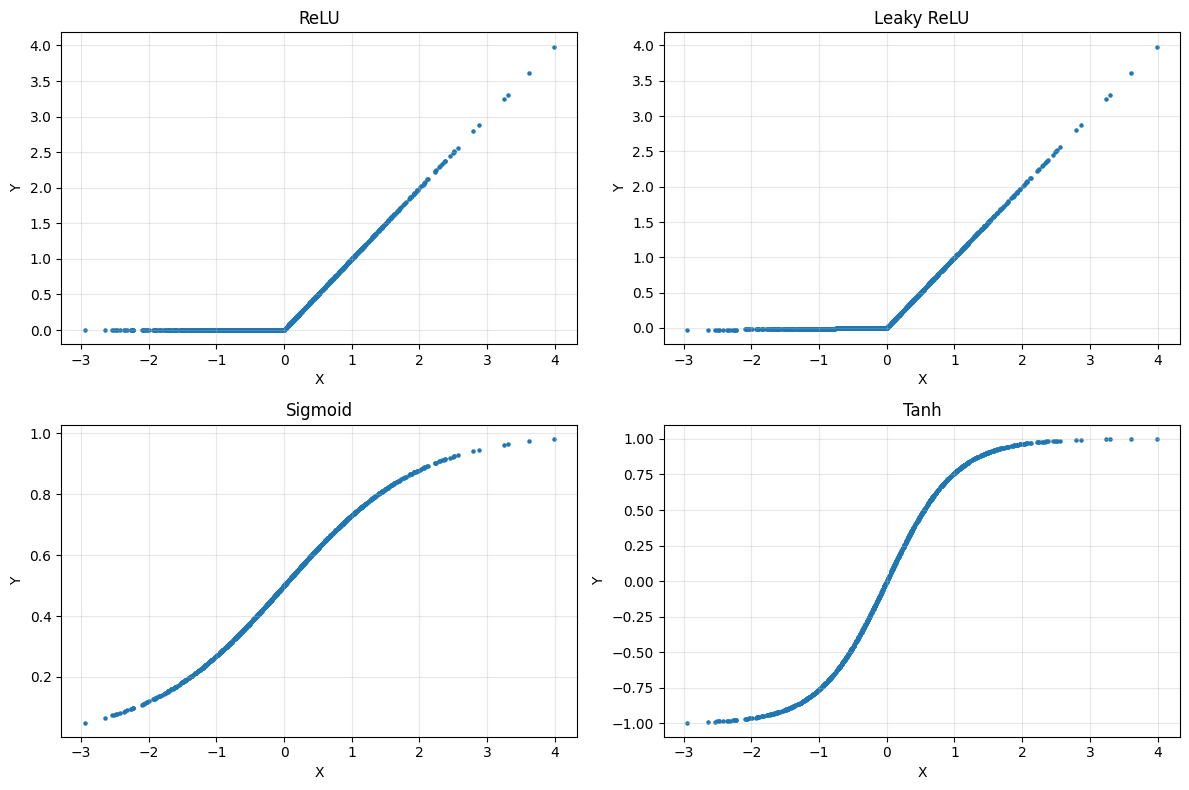

In [122]:
import torch
import matplotlib.pyplot as plt

x = torch.randn(1000)

# Функції активації
relu = torch.nn.ReLU()
leaky_relu = torch.nn.LeakyReLU(negative_slope=0.01)
sigmoid = torch.nn.Sigmoid()
tanh = torch.nn.Tanh()

# Обчислюємо Y
y_relu = relu(x)
y_leaky_relu = leaky_relu(x)
y_sigmoid = sigmoid(x)
y_tanh = tanh(x)

# Перетворюємо в numpy для побудови графіків
x_np = x.numpy()

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.scatter(x_np, y_relu.numpy(), s=5)
plt.title("ReLU")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(alpha=0.3)

plt.subplot(2, 2, 2)
plt.scatter(x_np, y_leaky_relu.numpy(), s=5)
plt.title("Leaky ReLU")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(alpha=0.3)

plt.subplot(2, 2, 3)
plt.scatter(x_np, y_sigmoid.numpy(), s=5)
plt.title("Sigmoid")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(alpha=0.3)

plt.subplot(2, 2, 4)
plt.scatter(x_np, y_tanh.numpy(), s=5)
plt.title("Tanh")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

6. Кількість параметрів нейронної мережі визначається кількістю ваг та bias у всіх повнозв'язаних шарах. Для архітектури 7→64→32→1 перший шар має 7*64+64=512 параметрів, другий - 64*32+32=2080, третій - 32*1+1=33. Загалом 512+2080+33=2625.
7. Кількість 200 епох можна вважати достатньою. Приблизно після 50–70 епох train loss та validation loss стають близькими, проте validation loss продовжує поступово зменшуватися до кінця навчання. Це свідчить про те, що модель не має явного перенавчання, хоча після 70+- епох покращення стає повільнішим. Тому збільшення кількості епох можливе, але очікувати значного покращення результату не варто.


---
## 1. Датасети

Ви отримаєте один з 10 датасетів нижче. Усі — задачі регресії на Hugging Face: табличні дані, здебільшого числові ознаки, від кількасот до кількадесяти тисяч рядків.

1. **[King County House Sales](https://huggingface.co/datasets/kraina/house_sales_in_king_county)** — 21 613 продажів будинків (Вашингтон, 2014–2015). Таргет: `price`. ⚠️ `load_dataset("kraina/house_sales_in_king_county")` не працює (застарілий loading-скрипт) — вантажте напряму: `load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")`.
2. **[Diamonds](https://huggingface.co/datasets/jdxcosta/diamonds)** — 53 940 діамантів. Таргет: `price`. Ознаки: вага (`carat`), огранка, колір, чистота, розміри.
3. **[Concrete Compressive Strength](https://huggingface.co/datasets/foundry-ml/dataset_concrete_compressive_strength)** — 1 030 замісів бетону. Таргет: міцність на стиск. Усі ознаки числові (склад суміші + вік).
4. **[Auto MPG](https://huggingface.co/datasets/scikit-learn/auto-mpg)** — 398 автомобілів. Таргет: `mpg` (витрата пального). Найменший і найпростіший датасет зі списку.
5. **[Wine Quality](https://huggingface.co/datasets/codesignal/wine-quality)** — 1 599 (червоне) + 4 898 (біле) вин. Таргет: `quality` (оцінка 3–9). Усі ознаки — хімічний склад, числові.
6. **[Laptop Price](https://huggingface.co/datasets/Ammok/laptop_price_prediction)** — 977 + 325 ноутбуків. Таргет: `Price`. Частина ознак текстові (`RAM`, `Storage`, `CPU`) — доведеться парсити в числа.
7. **[Bike Sharing Demand](https://huggingface.co/datasets/t22000t/bike-sharing-tabular)** — 17 379 годинних записів прокату велосипедів. Таргет: `cnt`. Часові й погодні ознаки.
8. **[Ames House Prices](https://huggingface.co/datasets/t22000t/house-prices-tabular)** — 1 460 будинків, 79 ознак. Таргет: `SalePrice`. Найбільше категоріальних ознак зі списку — гарна практика на encoding.
9. **[Medical Insurance Cost](https://huggingface.co/datasets/harishsohani/medical-insurance-cost-prediction)** — 1 338 застрахованих. Таргет: `charges`. Компактний, мало ознак — хороший старт, якщо часу мало. ⚠️ У репозиторії кілька CSV одразу (`Xtrain`/`Xtest`/`insurance.csv`) — вкажіть файл явно: `load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")`.
10. **[Abalone](https://huggingface.co/datasets/mstz/abalone)** — 4 177 молюсків. Таргет: `number_of_rings` (вік). Усі ознаки — фізичні виміри, окрім `sex`.

Решта (2–5, 7–8, 10) вантажаться напряму — `load_dataset("<repo_id>")` без додаткових аргументів, HF-токен не потрібен.

### 1.1. Який датасет мій?

Визначте самі власний датасет: беремо Ваше ПІБ, рахуємо SHA-256 хеш, залишок від ділення на 10 — це індекс у списку датасетів вище (0 → перший, 9 → останній).

**Формат ПІБ:** точно як у списку групи — `Прізвище Ім'я По-батькові`, по одному пробілу між словами, без зайвих пробілів на початку/в кінці. Якщо використаєте інший формат - **не зарахую лабу**!!!

In [123]:
import hashlib

DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Сапацінський Богдан Ігорович"  # TODO: впишіть своє ПІБ точно як у списку групи

dataset_index = int(hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])

Ваш датасет (#7): Bike Sharing Demand


---
## 2. Що потрібно зробити

Нижче — загальний план роботи, без коду: код і пояснення до кожного кроку дивіться в **демо-ноутбуці лекції 3-4**, номери розділів позначені в дужках. Ваша задача — повторити той самий підхід на своєму датасеті, а не скопіювати код один в один: у вашого датасету інші колонки, інші типи пропусків (чи їх взагалі нема), інші викиди (чи їх нема) — рішення на кожному кроці обґрунтовуйте під свої дані, а не тому, що "так було в демо".

### 2.1. Підготовка даних

1. Завантажте свій датасет (демо 1.1) і перетворіть на `pandas.DataFrame` (1.2).
2. Зробіть спліт **train / val / test** одразу, до будь-якого аналізу (1.3) — і поясніть своїми словами, чому саме в такому порядку (нагадування: data leakage).
3. Загальний огляд (`head`/`info`/`describe`, 1.4).
4. Обробка пропусків (1.5) — **якщо вони є**. Немає пропусків — так і напишіть, це теж валідний результат, не треба їх штучно вигадувати.
5. EDA (1.6): хоча б гістограми і кореляційна матриця. Що впадає в очі у ваших даних — capping, скошені розподіли, мультиколінеарність?
6. Обробка викидів (1.7) — **за потреби**, з обґрунтуванням: звідки взявся викид і чому саме таке рішення (видалити / трансформувати / залишити).
7. Інженерія ознак (1.8) — **за потреби**: чи є сенс комбінувати/прибирати ознаки з високою кореляцією між собою.

### 2.2. Baseline: множинна лінійна регресія

Стандартизація ознак (2.1), тензори (2.2), тренування `nn.Linear` (2.3), крива навчання (2.4), метрики на test — MSE/RMSE/MAE/R² (2.5), інтерпретація ваг (2.6).

Це ваш **варіант #1**, точка відліку для всього, що далі.

### 2.3. Нейромережа: щонайменше 2 різні архітектури

За зразком розділу 3 демо: `nn.Sequential` з прихованими шарами, ReLU, оптимізатор Adam.

Спробуйте **мінімум 2 архітектури**, які відрізняються не косметично — напр. різна кількість шарів, різна ширина шарів, чи інша функція активації (3.2). Кожна — окремий варіант.

### 2.4. Підбір гіперпараметрів: щонайменше 3 зміни

Візьміть архітектуру, яка показала себе краще, і поекспериментуйте з гіперпараметрами: learning rate, оптимізатор (SGD/Adam), кількість епох, розмір batch (якщо вирішите його ввести) тощо. Змінюйте **по одному параметру за раз** — інакше не зрозумієте, що саме вплинуло на результат.

**Разом (2.2 + 2.3 + 2.4):** щонайменше 5 варіантів моделі (1 лінійна + 2 архітектури + 2 гіперпараметри), до **10 варіантів** — якщо є час і бажання поекспериментувати більше, це тільки заохочується.

### 2.5. Логування і порівняння

Кожен варіант (2.2-2.4) логуйте в TensorBoard в окрему підпапку `RUNS_DIR` (як у 2.3/3.5 демо) — з осмисленою назвою (`linear`, `nn_v1_2layers`, `nn_v2_deeper`, `nn_v2_lr_0.001`, ...), щоб потім усі криві можна було накласти одна на одну (3.8 демо) і візуально порівняти.

Наприкінці зведіть усі варіанти в одну таблицю (модель → MSE/RMSE/MAE/R² на test) і дайте коротку письмову відповідь:
- Яка модель перемогла і наскільки суттєво?
- Чи виправдала себе нейромережа порівняно з лінійною регресією на вашому датасеті?
- Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?

In [124]:

from google.colab import drive
import os
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab2"
os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


# 2.1 Підготовка даних

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab2


In [125]:
#1 Завантажте свій датасет (демо 1.1)
!pip install -q datasets

from datasets import load_dataset

HF_REPO_ID = "t22000t/bike-sharing-tabular"

bike_dataset = load_dataset(HF_REPO_ID)

print(bike_dataset)

DatasetDict({
    train: Dataset({
        features: ['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt'],
        num_rows: 17379
    })
})


In [126]:
#і перетворіть на pandas.DataFrame (1.2).
import pandas as pd

df = bike_dataset["train"].to_pandas()

print(df.shape)
display(df.head())

(17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Перевірка чи дані точно послідовні на випадок якщо візуального огляду не було достатньо.

In [127]:

# Перевірка хронологічного порядку даних

df["dteday"] = pd.to_datetime(df["dteday"])

# Формуємо повну часову мітку: дата + година
timestamps = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")

print("Кількість записів:", len(df))
print("Перша часова мітка:", timestamps.min())
print("Остання часова мітка:", timestamps.max())

print(
    "Дані вже відсортовані за часом:",
    timestamps.is_monotonic_increasing
)

print(
    "Кількість дублікатів часових міток:",
    timestamps.duplicated().sum()
)

# Перевірка пропущених годин
sorted_timestamps = timestamps.sort_values().reset_index(drop=True)
time_diffs = sorted_timestamps.diff().dropna()

print(
    "Кількість проміжків, довших за 1 годину:",
    (time_diffs > pd.Timedelta(hours=1)).sum()
)

# Якщо порядок порушено, показуємо перші місця порушення
if not timestamps.is_monotonic_increasing:
    print("\nПерші рядки, де порушено хронологічний порядок:")

    out_of_order = timestamps.diff() < pd.Timedelta(0)
    display(
        df.loc[out_of_order, ["dteday", "hr"]].head(10)
    )

Кількість записів: 17379
Перша часова мітка: 2011-01-01 00:00:00
Остання часова мітка: 2012-12-31 23:00:00
Дані вже відсортовані за часом: True
Кількість дублікатів часових міток: 0
Кількість проміжків, довших за 1 годину: 75


In [128]:
# Хронологічне розбиття: 60% / 20% / 20%

n = len(df)
train_end = int(n * 0.6)
val_end = int(n * 0.8)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print(f"Train: {train_df.shape}")
print(f"Validation: {val_df.shape}")
print(f"Test: {test_df.shape}")

Train: (10427, 17)
Validation: (3476, 17)
Test: (3476, 17)


In [129]:

def get_timestamps(data):
    return (
        pd.to_datetime(data["dteday"])
        + pd.to_timedelta(data["hr"], unit="h")
    )

for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    ts = get_timestamps(part)
    print(
        f"{name}: {ts.min()} — {ts.max()} | "
        f"Порядок: {ts.is_monotonic_increasing}"
    )

print(
    "\nTrain → Validation:",
    get_timestamps(train_df).max()
    < get_timestamps(val_df).min()
)

print(
    "Validation → Test:",
    get_timestamps(val_df).max()
    < get_timestamps(test_df).min()
)

Train: 2011-01-01 00:00:00 — 2012-03-15 13:00:00 | Порядок: True
Validation: 2012-03-15 14:00:00 — 2012-08-07 11:00:00 | Порядок: True
Test: 2012-08-07 12:00:00 — 2012-12-31 23:00:00 | Порядок: True

Train → Validation: True
Validation → Test: True


### **Розділення датасету на вибірки**

Спочатку виконуємо розділення датасету на навчальну (`train`), валідаційну (`validation`) та тестову (`test`) вибірки у співвідношенні 60% / 20% / 20%. Оскільки датасет містить погодинні спостереження за 2011–2012 роки, для розділення використовується хронологічний підхід: перші 60% записів відводяться для навчання, наступні 20% — для валідації, а останні 20% — для тестування.

Такий підхід дає змогу зберегти часову послідовність даних і перевірити здатність моделі працювати з пізнішими спостереженнями, яких не було в навчальній вибірці. На відміну від випадкового розділення за допомогою `train_test_split()`, хронологічне розбиття запобігає потраплянню пізніших спостережень у навчальну вибірку раніше за спостереження з валідаційної або тестової вибірки.

Після розділення аналіз та попередня обробка виконуються з урахуванням призначення кожної вибірки. Зокрема, параметри стандартизації обчислюються лише на навчальних даних, а потім застосовуються до валідаційної та тестової вибірок. Це допомагає уникнути витоку інформації (*data leakage*) та отримати об'єктивнішу оцінку узагальнювальної здатності моделі.


In [130]:
#Загальний огляд (head/info/describe, 1.4).
train_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [131]:
train_df.describe()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,10427.000000,10427,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000
mean,5214.000000,2011-08-09 17:17:42.357341696,2.254915,0.170902,5.754675,11.560756,0.029635,2.999233,0.682843,1.435216,0.459676,0.442653,0.630670,0.195572,26.328858,118.468016,144.796874
min,1.000000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2607.500000,2011-04-23 00:00:00,1.000000,0.000000,2.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.300000,0.303000,0.470000,0.104500,3.000000,27.000000,32.000000
50%,5214.000000,2011-08-10 00:00:00,2.000000,0.000000,5.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.440000,0.439400,0.620000,0.194000,12.000000,93.000000,110.000000
75%,7820.500000,2011-11-27 00:00:00,3.000000,0.000000,9.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.620000,0.590900,0.790000,0.283600,34.000000,171.000000,213.000000
max,10427.000000,2012-03-15 00:00:00,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,0.960000,1.000000,1.000000,0.850700,272.000000,647.000000,782.000000
std,3010.159963,NaN,1.156655,0.376442,3.618913,6.908435,0.169585,2.003354,0.465392,0.652798,0.197383,0.177314,0.197766,0.125696,37.201028,112.652735,134.620655


In [132]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10427 entries, 0 to 10426
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     10427 non-null  int64         
 1   dteday      10427 non-null  datetime64[ns]
 2   season      10427 non-null  int64         
 3   yr          10427 non-null  int64         
 4   mnth        10427 non-null  int64         
 5   hr          10427 non-null  int64         
 6   holiday     10427 non-null  int64         
 7   weekday     10427 non-null  int64         
 8   workingday  10427 non-null  int64         
 9   weathersit  10427 non-null  int64         
 10  temp        10427 non-null  float64       
 11  atemp       10427 non-null  float64       
 12  hum         10427 non-null  float64       
 13  windspeed   10427 non-null  float64       
 14  casual      10427 non-null  int64         
 15  registered  10427 non-null  int64         
 16  cnt         10427 non-

In [133]:
#обробка-перевірка пропусків
train_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


In [134]:
train_df.isna().any().any()

np.False_

Пропусків немає, отже обробляти нічого не потрібно.

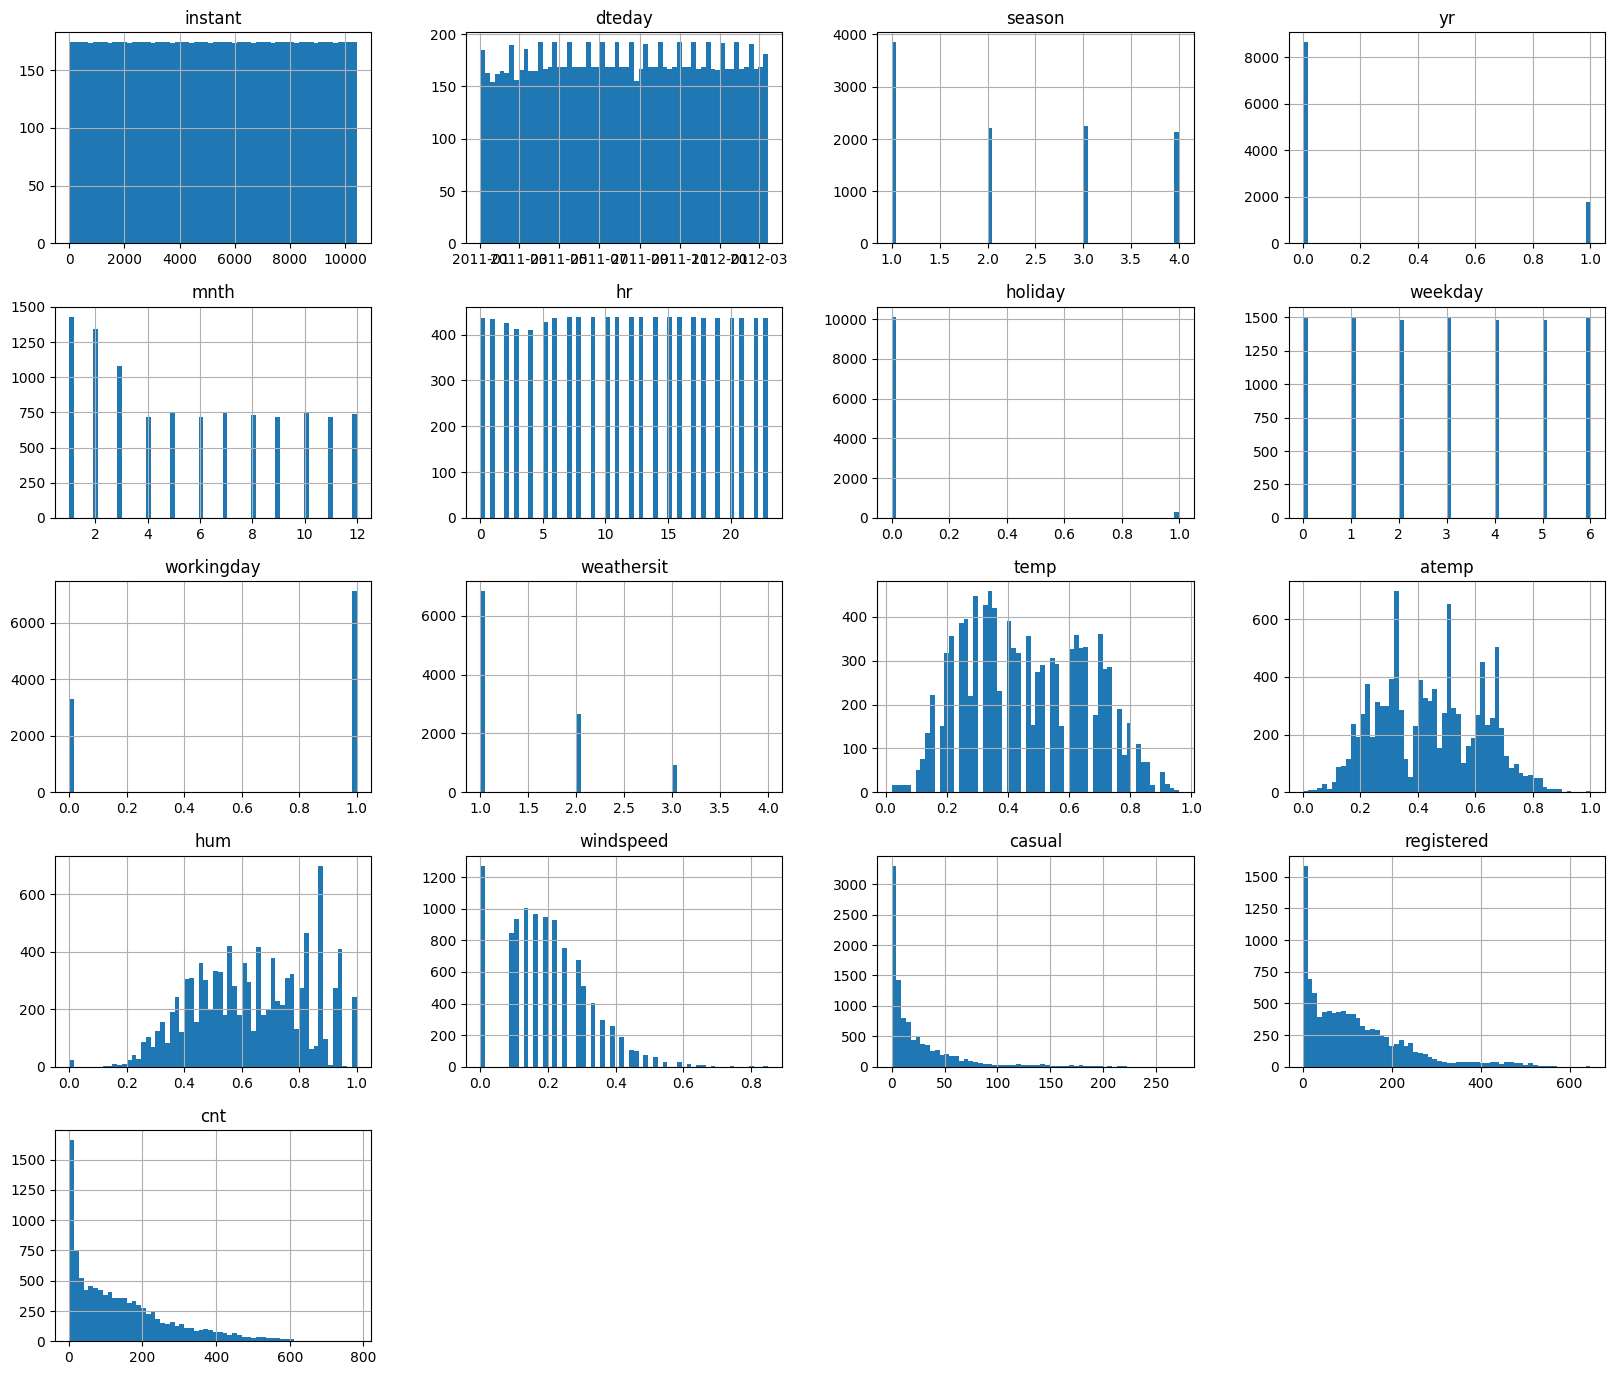

In [136]:
#EDA (1.6): хоча б гістограми і кореляційна матриця. Що впадає в очі у ваших даних — capping, скошені розподіли, мультиколінеарність?

train_df.hist(bins=60, figsize=(20, 17))
plt.show()

In [137]:
from scipy.stats import skew

# Перевірка найбільших значень
for col in ["casual", "registered", "cnt", "hum", "windspeed"]:
    print(f"{col} — найбільші значення:")
    print(train_df[col].value_counts().sort_index(ascending=False).head(5))
    print()

# Skewness за числовими колонками
print("Skewness за колонками:")

for col in train_df.select_dtypes(include="number").columns:
    print(f"{col}: {skew(train_df[col].dropna()):.2f}")

casual — найбільші значення:
casual
272    1
262    1
256    1
251    1
248    1
Name: count, dtype: int64

registered — найбільші значення:
registered
647    1
642    1
638    1
628    1
623    1
Name: count, dtype: int64

cnt — найбільші значення:
cnt
782    1
749    1
734    1
712    1
676    1
Name: count, dtype: int64

hum — найбільші значення:
hum
1.00    241
0.97      1
0.96      3
0.94    408
0.93    270
Name: count, dtype: int64

windspeed — найбільші значення:
windspeed
0.8507    2
0.8358    1
0.8060    2
0.7761    1
0.7463    2
Name: count, dtype: int64

Skewness за колонками:
instant: 0.00
season: 0.29
yr: 1.75
mnth: 0.25
hr: -0.01
holiday: 5.55
weekday: 0.00
workingday: -0.79
weathersit: 1.22
temp: 0.18
atemp: 0.11
hum: -0.08
windspeed: 0.58
casual: 2.53
registered: 1.41
cnt: 1.15


### **Аналіз розподілів ознак**

**Скошеність:** `casual`, `registered` і `cnt` мають правосторонню скошеність: більшість значень невеликі, а високі значення трапляються рідше. Це характерно для даних про попит на оренду велосипедів.

**Категоріальні змінні:** `holiday` має дисбаланс класів, оскільки більшість днів не є святковими. Розподіли `season`, `weekday` і `weathersit` оцінюються за гістограмами.

**Часові та надлишкові ознаки:** `hr` і `mnth` відображають часові закономірності попиту. Змінні `temp` та `atemp` можуть бути сильно корельованими, а `dteday`, `instant` і `yr` містять часову або порядкову інформацію.

**Межі значень:** `hum` і `windspeed` мають обмежені діапазони значень. Наявність граничних значень сама по собі не доводить обрізання даних.

**Висновок:** дані містять скошені розподіли, дисбаланс окремих категорій і потенційно надлишкові ознаки. Це потрібно врахувати під час підготовки даних до моделювання та перевірити за допомогою кореляційної матриці.


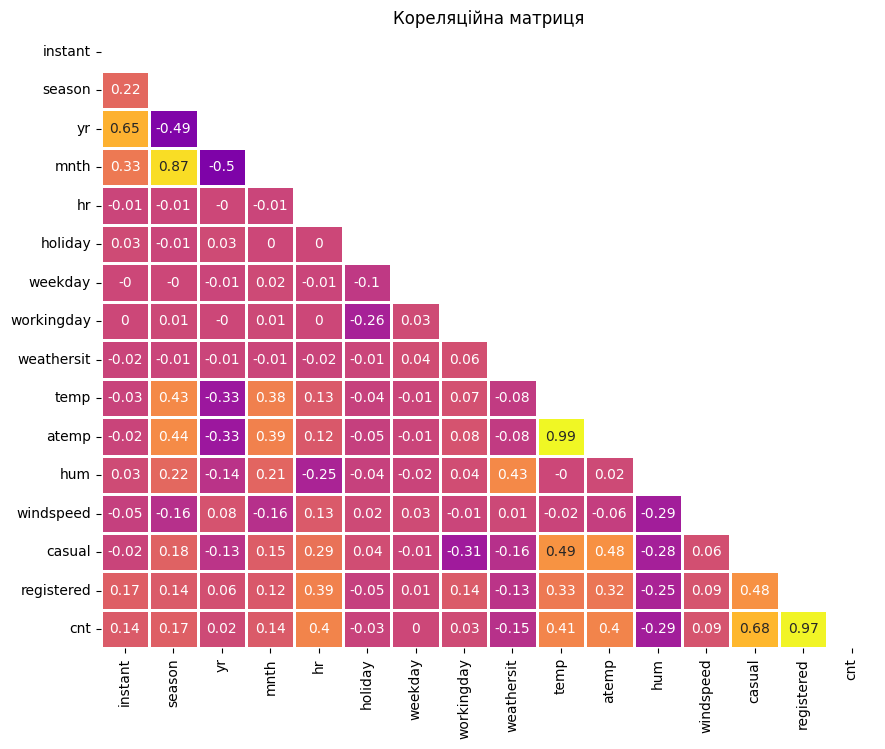

In [138]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Функція для побудови кореляційної матриці
def corr_mat(df):

    corr = df.corr(numeric_only=True).round(2)

    f, ax = plt.subplots(figsize=(10, 8))

    mask = np.zeros_like(corr, dtype=bool)
    mask[np.triu_indices_from(mask)] = True

    sns.heatmap(
        corr,
        mask=mask,
        vmin=-1,
        vmax=1,
        center=0,
        cmap="plasma",
        square=False,
        lw=2,
        annot=True,
        cbar=False
    )

    plt.title("Кореляційна матриця")
    plt.show()

corr_mat(train_df)

### 1.7. Обробка викидів


In [111]:
import pandas as pd

check_cols = [
    "casual", "registered", "cnt",
    "hum", "windspeed"
]

for col in check_cols:
    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = train_df[
        (train_df[col] < lower) |
        (train_df[col] > upper)
    ]

    print(
        f"{col}: "
        f"межі [{lower:.4f}, {upper:.4f}], "
        f"потенційних викидів: {len(outliers)}"
    )

casual: межі [-43.5000, 80.5000], потенційних викидів: 778
registered: межі [-189.0000, 387.0000], потенційних викидів: 434
cnt: межі [-239.5000, 484.5000], потенційних викидів: 276
hum: межі [-0.0100, 1.2700], потенційних викидів: 0
windspeed: межі [-0.1642, 0.5523], потенційних викидів: 78


Для виявлення потенційних викидів було застосовано метод міжквартильного розмаху (IQR). Він дає змогу визначити значення, які суттєво відрізняються від центральної частини розподілу.

Найбільшу кількість потенційних викидів виявлено у змінних `casual`, `registered` і `cnt`, що описують кількість оренд велосипедів. Це може бути пов'язано з асиметричним розподілом попиту та значними коливаннями кількості оренд протягом доби. Тому такі значення не обов'язково є помилковими.

У змінній `windspeed` виявлено 203 потенційні викиди, тоді як у `hum` — 0. Сам факт виходу за межі IQR не підтверджує наявності помилки: ці значення можуть відображати рідкісні, але реальні погодні умови.

Значення `windspeed` характеризують погодні умови, тому крайні значення можуть бути зумовлені природними явищами. Водночас можливість помилок у цих показниках доцільно перевірити окремо.

Для змінних `casual`, `registered` та `cnt` високі значення можуть пояснюватися природними коливаннями попиту на оренду велосипедів. Тому для подальшого аналізу було вирішено детальніше розглянути потенційні викиди саме у `windspeed`, щоб оцінити їхню правдоподібність.


###Перевіримо значення `windspeed`

In [112]:
col = "windspeed"

q1 = train_df[col].quantile(0.25)
q3 = train_df[col].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

mask = (train_df[col] < lower) | (train_df[col] > upper)

print(f"Межі IQR: [{lower:.4f}, {upper:.4f}]")
print("Кількість потенційних викидів:", mask.sum())
print("Мінімальне значення windspeed:", train_df[col].min())
print("Максимальне значення windspeed:", train_df[col].max())
print("Кількість нульових значень:", (train_df[col] == 0).sum())

Межі IQR: [-0.1642, 0.5523]
Кількість потенційних викидів: 78
Мінімальне значення windspeed: 0.0
Максимальне значення windspeed: 0.8507
Кількість нульових значень: 1271


Виведемо потенційні викиди для перевірки:

In [113]:
col = "windspeed"

q1 = train_df[col].quantile(0.25)
q3 = train_df[col].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

mask = (train_df[col] < lower) | (train_df[col] > upper)

cols = [
    "dteday", "season", "mnth", "hr", "weathersit",
    "temp", "hum", "windspeed", "cnt"
]

print(
    train_df.loc[mask, cols]
    .sort_values("windspeed", ascending=False)
    .head(20)
)

          dteday  season  mnth  hr  weathersit  temp   hum  windspeed  cnt
4316  2011-07-03       3     7  18           3  0.80  0.49     0.8507  181
4315  2011-07-03       3     7  17           3  0.80  0.49     0.8507  358
5635  2011-08-27       3     8  17           3  0.64  0.89     0.8358   16
1259  2011-02-25       1     2  15           1  0.46  0.41     0.8060   55
9956  2012-02-24       1     2  21           1  0.42  0.35     0.8060  152
1017  2011-02-15       1     2   1           1  0.30  0.42     0.7761    5
1261  2011-02-25       1     2  17           1  0.32  0.49     0.7463  189
1125  2011-02-19       1     2  15           1  0.44  0.16     0.7463  171
9653  2012-02-12       1     2   4           2  0.10  0.46     0.7164    1
1018  2011-02-15       1     2   2           1  0.28  0.41     0.6866    3
9958  2012-02-24       1     2  23           1  0.38  0.37     0.6866   86
10261 2012-03-08       1     3  15           1  0.64  0.38     0.6866  185
9652  2012-02-12       1 

In [114]:
zero_wind = train_df[train_df["windspeed"] == 0]

print("Кількість записів із windspeed == 0:", len(zero_wind))
print("Частка у навчальній вибірці:", round(len(zero_wind) / len(train_df) * 100, 3), "%")

cols = [
    "dteday", "season", "mnth", "hr",
    "weathersit", "temp", "hum", "windspeed", "cnt"
]

print("\nПерші 20 записів із нульовою швидкістю вітру:")
print(zero_wind[cols].head(20))

Кількість записів із windspeed == 0: 1271
Частка у навчальній вибірці: 12.19 %

Перші 20 записів із нульовою швидкістю вітру:
        dteday  season  mnth  hr  weathersit  temp   hum  windspeed  cnt
0   2011-01-01       1     1   0           1  0.24  0.81        0.0   16
1   2011-01-01       1     1   1           1  0.22  0.80        0.0   40
2   2011-01-01       1     1   2           1  0.22  0.80        0.0   32
3   2011-01-01       1     1   3           1  0.24  0.75        0.0   13
4   2011-01-01       1     1   4           1  0.24  0.75        0.0    1
6   2011-01-01       1     1   6           1  0.22  0.80        0.0    2
7   2011-01-01       1     1   7           1  0.20  0.86        0.0    3
8   2011-01-01       1     1   8           1  0.24  0.75        0.0    8
9   2011-01-01       1     1   9           1  0.32  0.76        0.0   14
64  2011-01-03       1     1  19           1  0.20  0.47        0.0  110
89  2011-01-04       1     1  21           1  0.22  0.64        0.0   4

In [115]:
zero_wind = train_df[train_df["windspeed"] == 0]

print("Кількість нульових значень за місяцями:")
print(zero_wind.groupby("mnth").size().reindex(range(1, 13), fill_value=0))

print("\nЧастка нульових значень від усіх записів кожного місяця (%):")
monthly_zero_pct = (
    train_df.assign(zero_wind=train_df["windspeed"] == 0)
    .groupby("mnth")["zero_wind"]
    .mean()
    .mul(100)
    .round(2)
)
print(monthly_zero_pct)

Кількість нульових значень за місяцями:
mnth
1     139
2     156
3      68
4      42
5      85
6      84
7      93
8     100
9     108
10    136
11    119
12    141
dtype: int64

Частка нульових значень від усіх записів кожного місяця (%):
mnth
1      9.73
2     11.63
3      6.30
4      5.84
5     11.42
6     11.67
7     12.50
8     13.68
9     15.06
10    18.30
11    16.55
12    19.03
Name: zero_wind, dtype: float64


### **Перевірка нульових значень швидкості вітру**

У змінній `windspeed` було виявлено 1271 нульових значень, що становить приблизно 12,19% навчальної вибірки. Для перевірки їхнього розподілу було проаналізовано кількість і частку таких записів за місяцями. Нульові значення трапляються протягом усього року, а їхня частка коливається від 5,84% до 19,03%.

Оскільки нульова швидкість вітру є фізично можливою, а перевірка не виявила очевидної концентрації таких значень в одному часовому проміжку, було вирішено залишити їх без змін.

### 1.8. Інженерія ознак

Кореляційна матриця показала високу кореляцію між `temp` та `atemp` (0,99), тому було вирішено видалити `atemp`, залишивши `temp`.

Змінні `casual` і `registered` не використовуються як ознаки, оскільки їхня сума дорівнює цільовій змінній `cnt`. Їх використання призвело б до витоку цільової інформації (*data leakage*).

Також видалено `instant`, який є порядковим ідентифікатором запису, та `dteday`, оскільки необхідні календарні характеристики представлені окремими змінними.

У результаті для подальшого моделювання залишено ознаки `season`, `yr`, `mnth`, `hr`, `holiday`, `weekday`, `workingday`, `weathersit`, `temp`, `hum` і `windspeed`. Цільовою змінною залишається `cnt`.


In [139]:
# Видаляємо зайві ознаки
columns_to_drop = ["atemp", "casual", "registered", "instant", "dteday"]

train_df = train_df.drop(columns=columns_to_drop)

# Виводимо назви ознак, що залишилися
print("Ознаки, що залишилися:")
print(train_df.columns.tolist())

Ознаки, що залишилися:
['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt']


###2.2. Baseline: множинна лінійна регресія

Стандартизація ознак (2.1), тензори (2.2), тренування nn.Linear (2.3), крива навчання (2.4), метрики на test — MSE/RMSE/MAE/R² (2.5), інтерпретація ваг (2.6).

In [117]:
from sklearn.preprocessing import StandardScaler

feature_cols = [c for c in train_df.columns if c not in ["cnt"]]

scaler = StandardScaler()

# Навчаємо scaler тільки на train
X_train = scaler.fit_transform(train_df[feature_cols])

# Для validation і test використовуємо той самий scaler лише transform
X_val = scaler.transform(val_df[feature_cols])
X_test = scaler.transform(test_df[feature_cols])

# Цільова змінна
y_train = train_df["cnt"].values
y_val = val_df["cnt"].values
y_test = test_df["cnt"].values

print("Ознаки:", feature_cols)
print("Форма X_train:", X_train.shape)

Ознаки: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed']
Форма X_train: (10427, 11)


###Перетворюєм у тензори

In [118]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def to_tensor(X, y):
    return (
        torch.tensor(X, dtype=torch.float32).to(device),
        torch.tensor(y, dtype=torch.float32).unsqueeze(1).to(device),
    )

# Перетворюємо train, validation та test у тензори
x_train_t, y_train_t = to_tensor(X_train, y_train)
x_val_t, y_val_t = to_tensor(X_val, y_val)
x_test_t, y_test_t = to_tensor(X_test, y_test)

print("X_train:", x_train_t.shape)
print("y_train:", y_train_t.shape)
print("X_val:", x_val_t.shape)
print("y_val:", y_val_t.shape)
print("X_test:", x_test_t.shape)
print("y_test:", y_test_t.shape)

X_train: torch.Size([10427, 11])
y_train: torch.Size([10427, 1])
X_val: torch.Size([3476, 11])
y_val: torch.Size([3476, 1])
X_test: torch.Size([3476, 11])
y_test: torch.Size([3476, 1])


###Тренування nn.Linear (2.3)

In [140]:
from torch.utils.tensorboard import SummaryWriter

N_EPOCHS = 50

# Кількість вхідних ознак
n_features = X_train.shape[1]

# Лінійна модель
linear_model = torch.nn.Linear(
    in_features=n_features,
    out_features=1
).to(device)

optimizer = torch.optim.SGD(
    linear_model.parameters(),
    lr=0.1
)

loss_fn = torch.nn.MSELoss()

writer = SummaryWriter(
    log_dir=os.path.join(RUNS_DIR, "linear_regression")
)

train_losses, val_losses = [], []

for epoch in range(N_EPOCHS):
    # Навчання
    linear_model.train()
    optimizer.zero_grad()

    y_pred = linear_model(x_train_t)
    loss = loss_fn(y_pred, y_train_t)

    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    # Валідація
    linear_model.eval()

    with torch.no_grad():
        val_loss = loss_fn(
            linear_model(x_val_t),
            y_val_t
        ).item()

    val_losses.append(val_loss)

    # Запис у TensorBoard
    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 3 == 0 or epoch == N_EPOCHS - 1:
        print(
            f"epoch {epoch:4d}  "
            f"train_loss={loss.item():.4f}  "
            f"val_loss={val_loss:.4f}"
        )

writer.close()

epoch    0  train_loss=39093.6211  val_loss=91915.4922
epoch    3  train_loss=18308.0938  val_loss=55169.4961
epoch    6  train_loss=13369.1348  val_loss=42526.3984
epoch    9  train_loss=12072.5547  val_loss=37826.8945
epoch   12  train_loss=11711.8262  val_loss=35916.5000
epoch   15  train_loss=11605.8936  val_loss=35067.2031
epoch   18  train_loss=11572.7295  val_loss=34656.7891
epoch   21  train_loss=11561.5088  val_loss=34443.5195
epoch   24  train_loss=11557.3662  val_loss=34325.8906
epoch   27  train_loss=11555.6934  val_loss=34257.8945
epoch   30  train_loss=11554.9580  val_loss=34217.1562
epoch   33  train_loss=11554.6104  val_loss=34192.0820
epoch   36  train_loss=11554.4307  val_loss=34176.3516
epoch   39  train_loss=11554.3311  val_loss=34166.3398
epoch   42  train_loss=11554.2725  val_loss=34159.9141
epoch   45  train_loss=11554.2354  val_loss=34155.7656
epoch   48  train_loss=11554.2080  val_loss=34153.1055
epoch   49  train_loss=11554.2021  val_loss=34152.4492


###Крива навчання


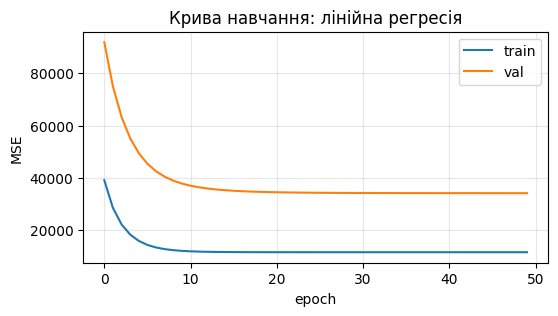

In [141]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 3))

plt.plot(train_losses, label="train")
plt.plot(val_losses, label="val")

plt.xlabel("epoch")
plt.ylabel("MSE")
plt.title("Крива навчання: лінійна регресія")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Метрики на test — MSE/RMSE/MAE/R² (2.5)

In [121]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Переводимо модель у режим оцінювання
linear_model.eval()

with torch.no_grad():
    y_test_pred = linear_model(x_test_t).cpu().numpy().flatten()

# Бейзлайн: для всіх об'єктів прогнозуємо середнє значення train
baseline_pred = np.full_like(y_test, y_train.mean())


def report(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = mse ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    print(
        f"{name:14s} "
        f"MSE={mse:.4f}  "
        f"RMSE={rmse:.4f}  "
        f"MAE={mae:.4f}  "
        f"R2={r2:.4f}"
    )


report(y_test, baseline_pred, "Бейзлайн")
report(y_test, y_test_pred, "Лін. регресія")

Бейзлайн       MSE=59587.0814  RMSE=244.1047  MAE=179.6620  R2=-0.2257
Лін. регресія  MSE=35147.7773  RMSE=187.4774  MAE=139.7474  R2=0.2770


Лінійна регресія показала кращі результати порівняно з бейзлайном за всіма розглянутими метриками. Значення `MAE` становить `139,75`, а коефіцієнт детермінації `R²` — `0,277`. Отже, модель виявляє залежності між ознаками та попитом на велосипеди, проте її точність залишається обмеженою. Це може бути пов’язано з нелінійністю залежностей і зміною попиту залежно від часу доби та сезону.


In [142]:
# Каталог для моделей
MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
os.makedirs(MODELS_DIR, exist_ok=True)

# Шлях до файлу моделі
MODEL_PATH = os.path.join(MODELS_DIR, "linear.pt")

# Зберігаємо параметри навченої моделі
torch.save(linear_model.state_dict(), MODEL_PATH)

print("Модель збережено:", MODEL_PATH)

Модель збережено: /content/drive/MyDrive/ai_systems/lab2/models/linear.pt


###Інтерпретація ваг 2.6

In [143]:
weights = linear_model.weight.detach().cpu().numpy().flatten()

weight_df = pd.DataFrame({
    "feature": feature_cols,
    "weight": weights
})

weight_df["abs_weight"] = weight_df["weight"].abs()

weight_df = weight_df.sort_values(
    "abs_weight", ascending=False
).drop(columns="abs_weight")

print(weight_df.to_string(index=False))

   feature     weight
      temp  48.845539
        hr  41.245102
       hum -27.262333
        yr  24.654531
    season  14.059240
      mnth   6.504568
   holiday  -3.643595
weathersit  -3.168794
 windspeed   1.275886
   weekday   0.879210
workingday   0.781898


**Інтерпретація ваг моделі.** Найбільші за абсолютною величиною ваги отримали ознаки `temp` (48,85), `hr` (41,25) та `hum` (-27,26). Це вказує на їхню значущість для прогнозу в межах побудованої лінійної моделі. Додатні ваги `temp`, `hr` і `yr` означають позитивний зв’язок із прогнозом, тоді як від’ємна вага `hum` вказує на зворотний зв’язок за інших рівних умов. Найменші ваги мають `weekday` і `workingday`, тому їхній лінійний внесок у прогноз є відносно невеликим. Водночас ці результати відображають залежності, які модель змогла описати, і не доводять причинного впливу ознак.


### 2.3. Нейромережа: щонайменше 2 різні архітектури

### Архітектура нейромережі NN_v1

Для першого варіанта нейромережі використано архітектуру з двома прихованими шарами, запозичену з демонстраційного прикладу та адаптовану до задачі прогнозування кількості прокатів велосипедів.

Архітектура має вигляд **11 → 64 → 32 → 1**:

* **Вхідний шар:** 11 стандартизованих ознак датасету.
* **Перший прихований шар:** 64 нейрони з функцією активації ReLU.
* **Другий прихований шар:** 32 нейрони з функцією активації ReLU.
* **Вихідний шар:** один нейрон, що прогнозує кількість прокатів велосипедів (`cnt`).

Модель реалізовано за допомогою `torch.nn.Sequential`. Для навчання використано оптимізатор Adam зі швидкістю навчання 0.01, функцію втрат MSE та 200 епох. Додаткове створення ознак не виконувалося — використано ті самі стандартизовані ознаки, що й для лінійної регресії.

Кількість параметрів нейромережі становить **2881**, тоді як лінійна регресія має 12 параметрів. Мета цього експерименту — перевірити, чи дозволяє нелінійна модель отримати кращу якість прогнозування порівняно з базовою лінійною моделлю.


In [144]:
nn_v1 = torch.nn.Sequential(
    torch.nn.Linear(n_features, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
).to(device)

print(nn_v1)
print(
    "Кількість параметрів NN v1:",
    sum(p.numel() for p in nn_v1.parameters())
)
print(
    "Кількість параметрів лінійної регресії:",
    sum(p.numel() for p in linear_model.parameters())
)

Sequential(
  (0): Linear(in_features=11, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів NN v1: 2881
Кількість параметрів лінійної регресії: 12


###Навчання NN_v1

In [145]:

N_EPOCHS = 200

optimizer = torch.optim.Adam(nn_v1.parameters(), lr=0.01)
loss_fn = torch.nn.MSELoss()

writer = SummaryWriter(
    log_dir=os.path.join(RUNS_DIR, "nn_v1")
)

nn_v1_train_losses = []
nn_v1_val_losses = []

for epoch in range(N_EPOCHS):
    nn_v1.train()

    optimizer.zero_grad()
    y_pred = nn_v1(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()

    nn_v1_train_losses.append(loss.item())

    nn_v1.eval()
    with torch.no_grad():
        val_loss = loss_fn(
            nn_v1(x_val_t), y_val_t
        ).item()

    nn_v1_val_losses.append(val_loss)

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(
            f"epoch {epoch:4d}  "
            f"train_loss={loss.item():.4f}  "
            f"val_loss={val_loss:.4f}"
        )

writer.close()

epoch    0  train_loss=39062.9766  val_loss=116036.5312
epoch   10  train_loss=37190.9961  val_loss=111625.4141
epoch   20  train_loss=29222.5957  val_loss=93519.8359
epoch   30  train_loss=15027.0732  val_loss=55172.7266
epoch   40  train_loss=14225.1504  val_loss=37725.6953
epoch   50  train_loss=12027.9551  val_loss=43770.1406
epoch   60  train_loss=11845.7949  val_loss=39019.0742
epoch   70  train_loss=11707.1426  val_loss=35021.4531
epoch   80  train_loss=11565.9180  val_loss=36645.4492
epoch   90  train_loss=11504.0996  val_loss=36105.7656
epoch  100  train_loss=11451.3848  val_loss=35565.7461
epoch  110  train_loss=11402.3350  val_loss=35925.5977
epoch  120  train_loss=11361.0322  val_loss=35430.8750
epoch  130  train_loss=11325.5020  val_loss=35192.3867
epoch  140  train_loss=11293.9111  val_loss=34924.6445
epoch  150  train_loss=11265.4873  val_loss=34609.7109
epoch  160  train_loss=11238.7041  val_loss=34397.7656
epoch  170  train_loss=11212.3223  val_loss=34162.5234
epoch  1

###Крива навчання NN_v1

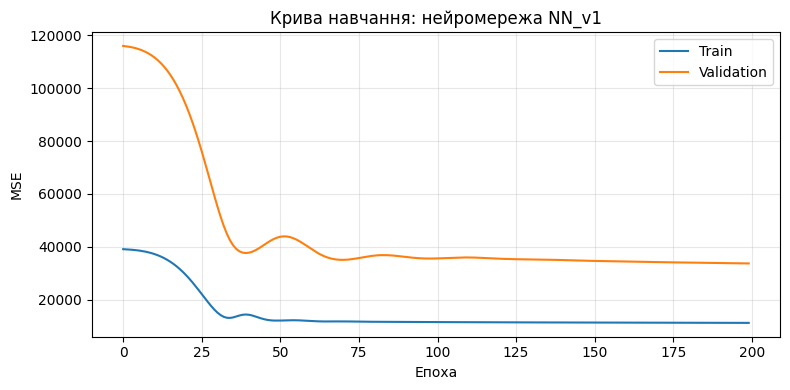

In [146]:
plt.figure(figsize=(8, 4))
plt.plot(nn_v1_train_losses, label="Train")
plt.plot(nn_v1_val_losses, label="Validation")
plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.title("Крива навчання: нейромережа NN_v1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Порівняння

In [147]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Прогноз нейромережі
nn_v1.eval()
with torch.no_grad():
    y_nn_v1_pred = nn_v1(x_test_t).cpu().numpy().flatten()

# Прогноз лінійної регресії вже обчислювали раніше:
# y_test_pred

def calculate_metrics(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        "Модель": name,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }

results = [
    calculate_metrics(y_test, baseline_pred, "Бейзлайн"),
    calculate_metrics(y_test, y_test_pred, "Лінійна регресія"),
    calculate_metrics(y_test, y_nn_v1_pred, "Нейромережа NN_v1")
]

metrics_df = pd.DataFrame(results)
print(metrics_df.round(4).to_string(index=False))

           Модель        MSE     RMSE      MAE      R2
         Бейзлайн 59587.0814 244.1047 179.6620 -0.2257
 Лінійна регресія 35147.7773 187.4774 139.7474  0.2770
Нейромережа NN v1 36663.2930 191.4766 134.2122  0.2458


In [148]:
nn_v1_path = os.path.join(MODELS_DIR, "nn_v1.pt")
torch.save(nn_v1.state_dict(), nn_v1_path)

print(f"Модель збережено: {nn_v1_path}")

Модель збережено: /content/drive/MyDrive/ai_systems/lab2/models/nn_v1.pt


### Порівняння лінійної регресії та нейромережі NN v1

За результатами оцінювання на тестовій вибірці лінійна регресія показала кращі результати за метриками MSE, RMSE та \(R^2\). Водночас нейромережа NN v1 отримала нижче значення MAE.

Лінійна регресія має MSE 35147.78, RMSE 187.48, MAE 139.75 та \(R^2 = 0.2770\). Для нейромережі NN v1 відповідні значення становлять 36663.29, 191.48, 134.21 та \(R^2 = 0.2458\).

Отже, у цьому експерименті складніша нейромережева архітектура не забезпечила загального покращення якості прогнозування порівняно з лінійною регресією. Проте нижче значення MAE свідчить, що NN v1 має меншу середню абсолютну похибку. Це показує, що ефективність моделі залежить не лише від складності архітектури, а й від характеру даних та налаштувань навчання.


###Архітектура NN v2

In [174]:
nn_v2 = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
).to(device)

print(nn_v2)
print(
    "Кількість параметрів NN v2:",
    sum(p.numel() for p in nn_v2.parameters())
)

Sequential(
  (0): Linear(in_features=11, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=32, bias=True)
  (5): ReLU()
  (6): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів NN v2: 11905


###Навчання NN_v2

Залишимо ті самі умови, що й для першої мережі: 200 епох, Adam із lr=0.01, MSE та ті самі навчальну й валідаційну вибірки.

In [175]:
N_EPOCHS = 200

optimizer_v2 = torch.optim.Adam(nn_v2.parameters(), lr=0.01)
loss_fn = torch.nn.MSELoss()

writer_v2 = SummaryWriter(
    log_dir=os.path.join(RUNS_DIR, "nn_v2_deeper")
)

nn_v2_train_losses = []
nn_v2_val_losses = []

for epoch in range(N_EPOCHS):
    nn_v2.train()

    optimizer_v2.zero_grad()
    y_pred = nn_v2(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer_v2.step()

    nn_v2_train_losses.append(loss.item())

    nn_v2.eval()
    with torch.no_grad():
        val_loss = loss_fn(nn_v2(x_val_t), y_val_t).item()

    nn_v2_val_losses.append(val_loss)

    writer_v2.add_scalar("Loss/train", loss.item(), epoch)
    writer_v2.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(
            f"epoch {epoch:4d}  "
            f"train_loss={loss.item():.4f}  "
            f"val_loss={val_loss:.4f}"
        )

writer_v2.close()

epoch    0  train_loss=39113.1758  val_loss=116058.7344
epoch   10  train_loss=28939.6016  val_loss=88058.3750
epoch   20  train_loss=15479.9668  val_loss=38345.5977
epoch   30  train_loss=12960.4141  val_loss=43614.5391
epoch   40  train_loss=11951.2832  val_loss=33341.5273
epoch   50  train_loss=11657.6162  val_loss=34086.1992
epoch   60  train_loss=11484.3809  val_loss=34788.4727
epoch   70  train_loss=11404.9756  val_loss=33776.4844
epoch   80  train_loss=11333.6729  val_loss=34443.2969
epoch   90  train_loss=11266.4883  val_loss=33721.3867
epoch  100  train_loss=11208.1484  val_loss=33337.2305
epoch  110  train_loss=11139.5342  val_loss=33187.3477
epoch  120  train_loss=11041.7168  val_loss=32901.0156
epoch  130  train_loss=10904.8691  val_loss=32534.1582
epoch  140  train_loss=10727.0254  val_loss=32098.9453
epoch  150  train_loss=10509.8652  val_loss=31616.6699
epoch  160  train_loss=10251.1230  val_loss=31069.0801
epoch  170  train_loss=9944.7549  val_loss=30389.0215
epoch  180

###Діаграма навчання NN_V2

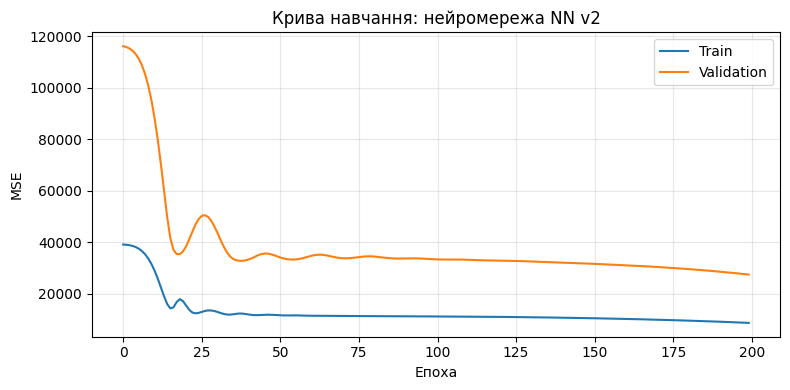

In [176]:
plt.figure(figsize=(8, 4))
plt.plot(nn_v2_train_losses, label="Train")
plt.plot(nn_v2_val_losses, label="Validation")
plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.title("Крива навчання: нейромережа NN v2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

###Метрики

In [177]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# Прогнози нейромереж
nn_v1.eval()
nn_v2.eval()

with torch.no_grad():
    y_nn_v1_pred = nn_v1(x_test_t).cpu().numpy().flatten()
    y_nn_v2_pred = nn_v2(x_test_t).cpu().numpy().flatten()

# y_test_pred — прогноз лінійної регресії з попереднього кроку
# baseline_pred — прогноз бейзлайну з попереднього кроку

def calculate_metrics(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        "Модель": name,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }

results = [
    calculate_metrics(y_test, baseline_pred, "Бейзлайн"),
    calculate_metrics(y_test, y_test_pred, "Лінійна регресія"),
    calculate_metrics(y_test, y_nn_v1_pred, "Нейромережа NN v1"),
    calculate_metrics(y_test, y_nn_v2_pred, "Нейромережа NN v2")
]

metrics_df = pd.DataFrame(results)
print(metrics_df.round(4).to_string(index=False))

           Модель        MSE     RMSE      MAE      R2
         Бейзлайн 59587.0814 244.1047 179.6620 -0.2257
 Лінійна регресія 35147.7773 187.4774 139.7474  0.2770
Нейромережа NN v1 36663.2930 191.4766 134.2122  0.2458
Нейромережа NN v2 28153.3809 167.7897 123.5688  0.4209


###Порівняння нейромережевих архітектур

За результатами тестування найкращі показники продемонструвала нейромережа `NN_v2` з трьома прихованими шарами (128, 64 і 32 нейрони). Вона отримала `MSE` = 28153.38, `RMSE` = 167.79, `MAE` = 123.57 та `R²` = 0.42.

Порівняно з лінійною регресією, `NN_v2` знизила `MSE`та `MAE`, на відміну від `NN_v1`, яка не перевершила лінійну модель за всіма метриками, глибша архітектура забезпечила краще прогнозування на тестовій вибірці.

In [178]:
nn_v2_path = os.path.join(MODELS_DIR, "nn_v2.pt")

torch.save(nn_v2.state_dict(), nn_v2_path)

print(f"Модель збережено: {nn_v2_path}")

Модель збережено: /content/drive/MyDrive/ai_systems/lab2/models/nn_v2.pt


#Експерименти

### Експеримент 1: learning rate = 0.001

In [155]:
torch.manual_seed(42)

nn_v2_lr001 = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
).to(device)

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(nn_v2_lr001.parameters(), lr=0.001)

epochs = 200

lr001_train_losses = []
lr001_val_losses = []

writer = SummaryWriter(os.path.join(RUNS_DIR, "nn_v2_lr_001"))

for epoch in range(epochs):
    nn_v2_lr001.train()

    train_pred = nn_v2_lr001(x_train_t)
    train_loss = criterion(train_pred, y_train_t)

    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    nn_v2_lr001.eval()

    with torch.no_grad():
        val_pred = nn_v2_lr001(x_val_t)
        val_loss = criterion(val_pred, y_val_t)

    lr001_train_losses.append(train_loss.item())
    lr001_val_losses.append(val_loss.item())

    writer.add_scalar("Loss/train", train_loss.item(), epoch)
    writer.add_scalar("Loss/validation", val_loss.item(), epoch)

    if epoch % 20 == 0 or epoch == epochs - 1:
        print(
            f"epoch {epoch:3d}  "
            f"train_loss={train_loss.item():.4f}  "
            f"val_loss={val_loss.item():.4f}"
        )

writer.close()

epoch   0  train_loss=39110.2969  val_loss=116244.1953
epoch  20  train_loss=38800.1289  val_loss=115508.6016
epoch  40  train_loss=37028.2852  val_loss=111250.5859
epoch  60  train_loss=30833.7109  val_loss=96253.6094
epoch  80  train_loss=18871.6348  val_loss=64107.5156
epoch 100  train_loss=13611.5820  val_loss=40863.9219
epoch 120  train_loss=12622.0352  val_loss=41569.2695
epoch 140  train_loss=12205.5625  val_loss=38703.1562
epoch 160  train_loss=11959.1729  val_loss=36745.1523
epoch 180  train_loss=11800.1592  val_loss=35888.9375
epoch 199  train_loss=11690.4004  val_loss=35146.1602


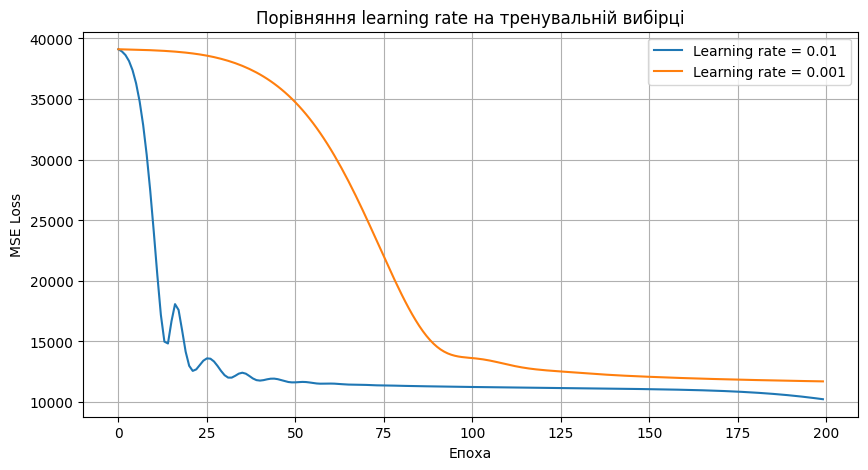

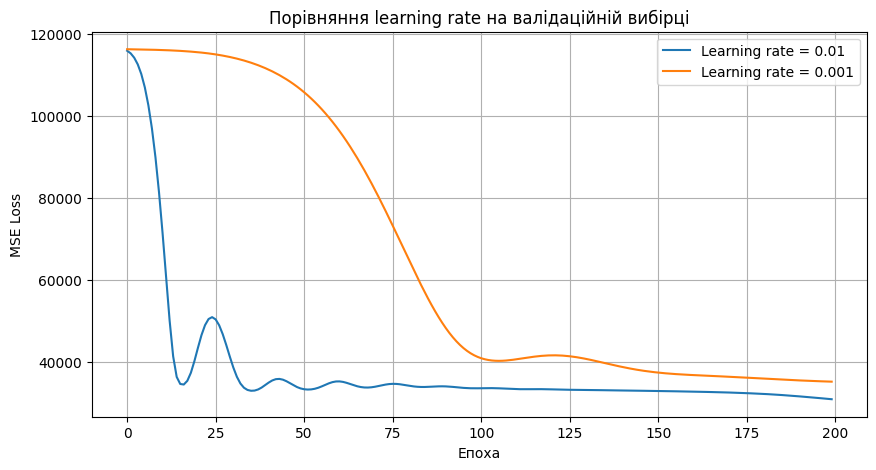

In [156]:
import matplotlib.pyplot as plt

# Порівняння train loss
plt.figure(figsize=(10, 5))
plt.plot(nn_v2_train_losses, label="Learning rate = 0.01")
plt.plot(lr001_train_losses, label="Learning rate = 0.001")
plt.xlabel("Епоха")
plt.ylabel("MSE Loss")
plt.title("Порівняння learning rate на тренувальній вибірці")
plt.legend()
plt.grid(True)
plt.show()

# Порівняння validation loss
plt.figure(figsize=(10, 5))
plt.plot(nn_v2_val_losses, label="Learning rate = 0.01")
plt.plot(lr001_val_losses, label="Learning rate = 0.001")
plt.xlabel("Епоха")
plt.ylabel("MSE Loss")
plt.title("Порівняння learning rate на валідаційній вибірці")
plt.legend()
plt.grid(True)
plt.show()

**Експеримент 1. Вплив learning rate на навчання нейронної мережі**

Під час експерименту було змінено швидкість навчання (learning rate) з 0.01 на 0.001. Архітектура нейронної мережі NN v2, оптимізатор Adam, функція втрат MSELoss та кількість епох (200) залишилися незмінними.

Для learning rate = 0.001 наприкінці навчання отримано train loss = 11690.40 та validation loss = 35146.16. Для базової моделі з learning rate = 0.01 відповідні значення становили 10217.08 та 30861.96.

За результатами експерименту базова модель із learning rate = 0.01 показала кращий результат за обома показниками. Зменшення швидкості навчання призвело до повільнішого зменшення функції втрат, і за 200 епох модель не змогла досягти такого самого рівня помилки.

**Висновок:** у межах проведеного експерименту learning rate = 0.01 виявився ефективнішим за 0.001. Тому для наступних експериментів значення 0.01 залишаємо базовим.


In [188]:
os.makedirs(MODELS_DIR, exist_ok=True)

torch.save(
    nn_v2_lr001.state_dict(),
    os.path.join(MODELS_DIR, "nn_v2_lr001.pt")
)

print("Модель nn_v2_lr001 збережено.")

Модель nn_v2_lr001 збережено.


### Експеримент 2: SGD замість Adam

Помітки:

при тестуванні з lr=0.01 результати після 10 епохи стали NaN

при тестуванні з lr=0.001 результати після 20 епохи стали NaN

In [182]:
torch.manual_seed(42)

nn_v2_sgd = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
).to(device)

criterion = torch.nn.MSELoss()
optimizer = torch.optim.SGD(nn_v2_sgd.parameters(), lr=0.0001)

epochs = 200

sgd_train_losses = []
sgd_val_losses = []

writer = SummaryWriter(os.path.join(RUNS_DIR, "nn_v2_sgd"))

for epoch in range(epochs):
    nn_v2_sgd.train()

    train_pred = nn_v2_sgd(x_train_t)
    train_loss = criterion(train_pred, y_train_t)

    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    nn_v2_sgd.eval()

    with torch.no_grad():
        val_pred = nn_v2_sgd(x_val_t)
        val_loss = criterion(val_pred, y_val_t)

    sgd_train_losses.append(train_loss.item())
    sgd_val_losses.append(val_loss.item())

    writer.add_scalar("Loss/train", train_loss.item(), epoch)
    writer.add_scalar("Loss/validation", val_loss.item(), epoch)

    if epoch % 20 == 0 or epoch == epochs - 1:
        print(
            f"epoch {epoch:3d}  "
            f"train_loss={train_loss.item():.4f}  "
            f"val_loss={val_loss.item():.4f}"
        )

writer.close()

epoch   0  train_loss=39110.2969  val_loss=116239.4766
epoch  20  train_loss=38792.7695  val_loss=115582.5938
epoch  40  train_loss=16087.0967  val_loss=44406.9688
epoch  60  train_loss=11555.9395  val_loss=34079.2734
epoch  80  train_loss=11298.1240  val_loss=33268.2109
epoch 100  train_loss=11052.1045  val_loss=32758.7871
epoch 120  train_loss=10623.6729  val_loss=31860.3906
epoch 140  train_loss=9699.8711  val_loss=29770.4512
epoch 160  train_loss=8308.8193  val_loss=26666.3516
epoch 180  train_loss=9567.5391  val_loss=38115.6172
epoch 199  train_loss=10478.7373  val_loss=23552.6680


###Графік навчання

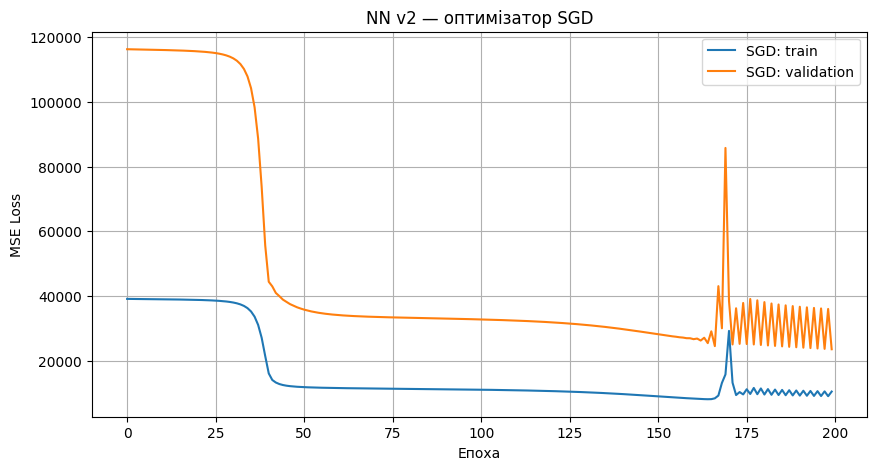

In [183]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(sgd_train_losses, label="SGD: train")
plt.plot(sgd_val_losses, label="SGD: validation")
plt.xlabel("Епоха")
plt.ylabel("MSE Loss")
plt.title("NN v2 — оптимізатор SGD")
plt.legend()
plt.grid(True)
plt.show()

In [187]:
nn_v2_sgd.eval()

with torch.no_grad():
    y_sgd_pred = nn_v2_sgd(x_test_t).cpu().numpy().flatten()

sgd_metrics = calculate_metrics(
    y_test,
    y_sgd_pred,
    "NN v2 — SGD"
)

pd.DataFrame([sgd_metrics]).round(4)

,Модель,MSE,RMSE,MAE,R2
0,NN v2 — SGD,23932.5801,154.7016,116.4803,0.5077


У результаті експерименту модель NN v2 з оптимізатором SGD показала кращі результати порівняно з початковою NN v2 з оптимізатором Adam. Було встановлено, що для стабільного навчання SGD необхідно використовувати малу швидкість навчання — у проведеному експерименті `lr = 0.0001`, оскільки за більших значень виникали помилки `NaN`.


In [189]:
os.makedirs(MODELS_DIR, exist_ok=True)

torch.save(
    nn_v2_sgd.state_dict(),
    os.path.join(MODELS_DIR, "nn_v2_sgd_lr0001.pt")
)

print("Модель nn_v2_sgd_lr0001. збережено.")

Модель nn_v2_sgd_lr0001. збережено.


### Експеримент: SGD з lr=0.0001 та 300 епох.

Примітка навчання з lr 0.00001 не ефеквтивне

In [195]:
torch.manual_seed(42)

nn_n2_sgd_lr0001_EP = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
).to(device)

criterion = torch.nn.MSELoss()
optimizer = torch.optim.SGD(
    nn_n2_sgd_lr0001_EP.parameters(),
    lr=0.0001
)

epochs = 300

sgd_lr0001_EP_train_losses = []
sgd_lr0001_EP_val_losses = []

writer = SummaryWriter(
    os.path.join(RUNS_DIR, "nn_n2_sgd_lr0001_EP")
)

for epoch in range(epochs):
    nn_n2_sgd_lr0001_EP.train()

    train_pred = nn_n2_sgd_lr0001_EP(x_train_t)
    train_loss = criterion(train_pred, y_train_t)

    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    nn_n2_sgd_lr0001_EP.eval()

    with torch.no_grad():
        val_pred = nn_n2_sgd_lr0001_EP(x_val_t)
        val_loss = criterion(val_pred, y_val_t)

    sgd_lr0001_EP_train_losses.append(train_loss.item())
    sgd_lr0001_EP_val_losses.append(val_loss.item())

    writer.add_scalar("Loss/train", train_loss.item(), epoch)
    writer.add_scalar("Loss/validation", val_loss.item(), epoch)

    if epoch % 20 == 0 or epoch == epochs - 1:
        print(
            f"epoch {epoch:3d}  "
            f"train_loss={train_loss.item():.4f}  "
            f"val_loss={val_loss.item():.4f}"
        )

writer.close()

epoch   0  train_loss=39110.2969  val_loss=116239.4766
epoch  20  train_loss=38792.7695  val_loss=115582.5938
epoch  40  train_loss=16087.0967  val_loss=44406.9688
epoch  60  train_loss=11555.9395  val_loss=34079.2734
epoch  80  train_loss=11298.1240  val_loss=33268.2109
epoch 100  train_loss=11052.1045  val_loss=32758.7871
epoch 120  train_loss=10623.6729  val_loss=31860.3906
epoch 140  train_loss=9699.8711  val_loss=29770.4512
epoch 160  train_loss=8308.8193  val_loss=26666.3516
epoch 180  train_loss=9567.5391  val_loss=38115.6172
epoch 200  train_loss=8999.5342  val_loss=35865.7969
epoch 220  train_loss=8623.2236  val_loss=35020.1172
epoch 240  train_loss=8311.3291  val_loss=34335.3008
epoch 260  train_loss=8048.9277  val_loss=33789.9492
epoch 280  train_loss=7814.5566  val_loss=33341.8789
epoch 299  train_loss=8785.4648  val_loss=19564.7695


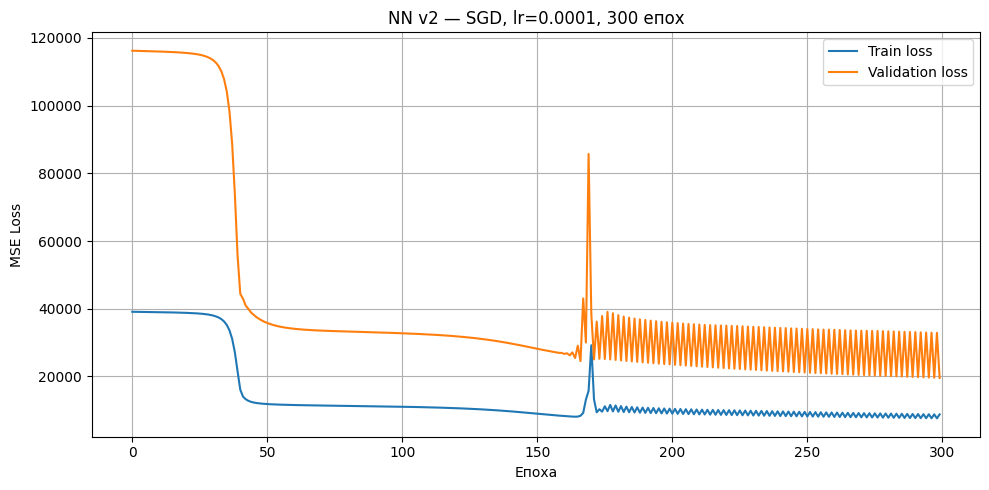

In [198]:
plt.figure(figsize=(10, 5))

plt.plot(sgd_lr0001_EP_train_losses, label="Train loss")
plt.plot(sgd_lr0001_EP_val_losses, label="Validation loss")

plt.xlabel("Епоха")
plt.ylabel("MSE Loss")
plt.title("NN v2 — SGD, lr=0.0001, 300 епох")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [199]:
nn_n2_sgd_lr0001_EP.eval()

with torch.no_grad():
    y_sgd_EP_pred = (
        nn_n2_sgd_lr0001_EP(x_test_t)
        .cpu()
        .numpy()
        .flatten()
    )

sgd_EP_metrics = calculate_metrics(
    y_test,
    y_sgd_EP_pred,
    "NN v2 — SGD, 300 епох"
)

pd.DataFrame([sgd_EP_metrics]).round(4)

,Модель,MSE,RMSE,MAE,R2
0,"NN v2 — SGD, 300 епох",20406.0117,142.8496,103.6017,0.5802


Збільшення кількості епох із 200 до 300 покращило якість прогнозування моделі NN v2 з оптимізатором SGD та lr = 0.0001. Водночас коливання валідаційної помилки свідчать, що навчання залишається нестабільним і можливе перенавчання.

In [200]:
# Збереження моделі
os.makedirs(MODELS_DIR, exist_ok=True)

torch.save(
    nn_n2_sgd_lr0001_EP.state_dict(),
    os.path.join(MODELS_DIR, "nn_n2_sgd_lr0001_EP.pt")
)

print("Модель nn_n2_sgd_lr0001_EP збережено.")

Модель nn_n2_sgd_lr0001_EP збережено.


###Експеримент — Early Stopping

In [214]:
import copy

torch.manual_seed(42)

# 1. Створення моделі NN v2
nn_n2_sgd_early = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
).to(device)

# 2. Функція втрат та оптимізатор
criterion = torch.nn.MSELoss()

optimizer = torch.optim.SGD(
    nn_n2_sgd_early.parameters(),
    lr=0.0001
)

# 3. Параметри навчання
max_epochs = 700
patience = 20

best_val_loss = float("inf")
best_epoch = 0
best_state = None
epochs_without_improvement = 0

early_train_losses = []
early_val_losses = []

# 4. TensorBoard
log_dir = os.path.join(
    RUNS_DIR,
    "nn_n2_sgd_early_stopping_v2"
)
writer = SummaryWriter(log_dir)

# 5. Цикл навчання
for epoch in range(max_epochs):
    nn_n2_sgd_early.train()

    # Прямий прохід і оновлення ваг
    optimizer.zero_grad()

    train_pred = nn_n2_sgd_early(x_train_t)
    loss = criterion(train_pred, y_train_t)

    loss.backward()
    optimizer.step()

    # Оцінюємо обидві втрати після оновлення ваг
    nn_n2_sgd_early.eval()

    with torch.no_grad():
        train_pred_eval = nn_n2_sgd_early(x_train_t)
        train_loss = criterion(train_pred_eval, y_train_t)

        val_pred = nn_n2_sgd_early(x_val_t)
        val_loss = criterion(val_pred, y_val_t)

    train_value = train_loss.item()
    val_value = val_loss.item()

    early_train_losses.append(train_value)
    early_val_losses.append(val_value)

    writer.add_scalar("Loss/train", train_value, epoch)
    writer.add_scalar("Loss/validation", val_value, epoch)

    # 6. Early Stopping: збереження найкращих ваг
    if val_value < best_val_loss:
        best_val_loss = val_value
        best_epoch = epoch
        best_state = copy.deepcopy(
            nn_n2_sgd_early.state_dict()
        )
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # 7. Виведення прогресу
    if epoch % 20 == 0 or epoch == max_epochs - 1:
        print(
            f"epoch {epoch:3d}  "
            f"train_loss={train_value:.4f}  "
            f"val_loss={val_value:.4f}  "
            f"best_epoch={best_epoch}"
        )

    # 8. Перевірка умови зупинки
    if epochs_without_improvement >= patience:
        print(
            f"\nEarly Stopping на епосі {epoch}. "
            f"Немає покращення протягом {patience} епох."
        )
        break

writer.close()

# 9. Відновлення найкращих ваг
if best_state is not None:
    nn_n2_sgd_early.load_state_dict(best_state)

epoch   0  train_loss=39098.8242  val_loss=116239.4766  best_epoch=0
epoch  20  train_loss=38760.8711  val_loss=115582.5938  best_epoch=20
epoch  40  train_loss=14059.0635  val_loss=44406.9688  best_epoch=40
epoch  60  train_loss=11538.6455  val_loss=34079.2734  best_epoch=60
epoch  80  train_loss=11286.9316  val_loss=33268.2109  best_epoch=80
epoch 100  train_loss=11036.9688  val_loss=32758.7871  best_epoch=100
epoch 120  train_loss=10592.3330  val_loss=31860.3906  best_epoch=120
epoch 140  train_loss=9635.1514  val_loss=29770.4512  best_epoch=140
epoch 160  train_loss=8249.7539  val_loss=26666.3516  best_epoch=160
epoch 180  train_loss=11242.5508  val_loss=38115.6172  best_epoch=166
epoch 200  train_loss=10426.2852  val_loss=35865.7969  best_epoch=199
epoch 220  train_loss=10029.5645  val_loss=35020.1172  best_epoch=219
epoch 240  train_loss=9666.5225  val_loss=34335.3008  best_epoch=239
epoch 260  train_loss=9327.9697  val_loss=33789.9492  best_epoch=259
epoch 280  train_loss=9028.4

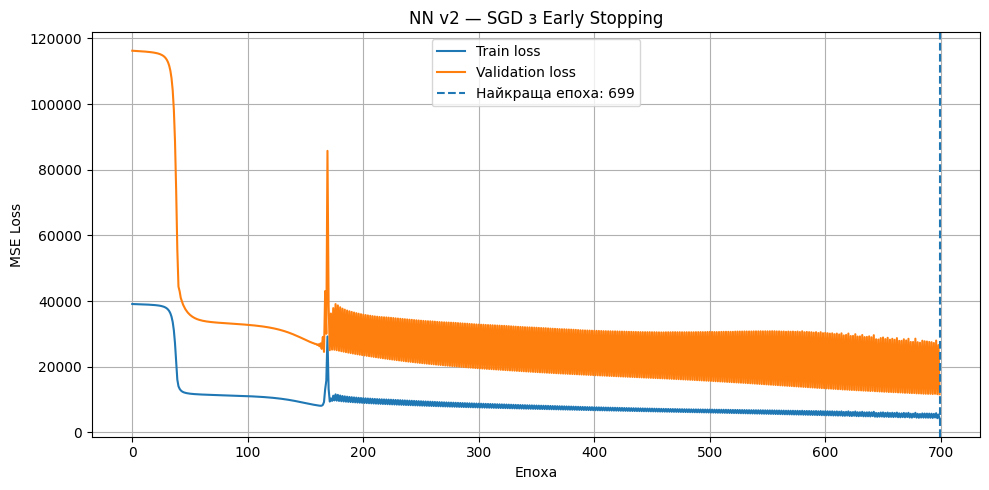

In [215]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(early_train_losses, label="Train loss")
plt.plot(early_val_losses, label="Validation loss")

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Найкраща епоха: {best_epoch}"
)

plt.xlabel("Епоха")
plt.ylabel("MSE Loss")
plt.title("NN v2 — SGD з Early Stopping")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [216]:
nn_n2_sgd_early.eval()

with torch.no_grad():
    y_early_pred = (
        nn_n2_sgd_early(x_test_t)
        .cpu()
        .numpy()
        .flatten()
    )

early_metrics = calculate_metrics(
    y_test,
    y_early_pred,
    "NN v2 — SGD + Early Stopping"
)

pd.DataFrame([early_metrics]).round(4)

,Модель,MSE,RMSE,MAE,R2
0,NN v2 — SGD + Early Stopping,14096.375,118.7282,76.6788,0.71


In [219]:
# Збереження моделі
os.makedirs(MODELS_DIR, exist_ok=True)

model_path = os.path.join(
    MODELS_DIR,
    "nn_n2_sgd_early_stopping.pt"
)

torch.save(
    nn_n2_sgd_early.state_dict(),
    model_path
)

print(f"\nНайкраща епоха: {best_epoch}")
print(f"Найкращий validation loss: {best_val_loss:.4f}")
print(f"Модель збережено: {model_path}")


Найкраща епоха: 699
Найкращий validation loss: 11625.9404
Модель збережено: /content/drive/MyDrive/ai_systems/lab2/models/nn_n2_sgd_early_stopping.pt


---
## 3. Gradio-застосунок: порівняння всіх варіантів наживо

Побудуйте аппку для своїх моделей

In [220]:
!pip install -q gradio plotly joblib

In [221]:
import os
import numpy as np
import pandas as pd
import torch
import gradio as gr
import plotly.express as px

# --------------------------------------------------
# 1. Налаштування
# --------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

feature_cols = [
    "season", "yr", "mnth", "hr", "holiday",
    "weekday", "workingday", "weathersit",
    "temp", "hum", "windspeed"
]

# Використовуємо scaler, навчений на train-вибірці
# у попередніх клітинках ноутбука.
assert len(feature_cols) == n_features, "Перевір n_features"

# Середня кількість оренд у train — бейзлайн.
baseline_value = float(np.mean(y_train))


# --------------------------------------------------
# 2. Архітектури моделей
# --------------------------------------------------

def make_linear_model():
    return torch.nn.Linear(n_features, 1)


def make_nn_v1():
    return torch.nn.Sequential(
        torch.nn.Linear(n_features, 64),
        torch.nn.ReLU(),
        torch.nn.Linear(64, 32),
        torch.nn.ReLU(),
        torch.nn.Linear(32, 1)
    )


def make_nn_v2():
    return torch.nn.Sequential(
        torch.nn.Linear(n_features, 128),
        torch.nn.ReLU(),
        torch.nn.Linear(128, 64),
        torch.nn.ReLU(),
        torch.nn.Linear(64, 32),
        torch.nn.ReLU(),
        torch.nn.Linear(32, 1)
    )


# --------------------------------------------------
# 3. Завантаження збережених моделей
# --------------------------------------------------

def load_model(model_factory, filename):
    path = os.path.join(MODELS_DIR, filename)

    if not os.path.exists(path):
        print(f"Файл не знайдено, модель пропущено: {path}")
        return None

    model = model_factory().to(device)
    state = torch.load(path, map_location=device, weights_only=True)
    model.load_state_dict(state)
    model.eval()

    print(f"Завантажено: {filename}")
    return model


models = {
    "Лінійна регресія": load_model(
        make_linear_model, "linear.pt"
    ),
    "Нейромережа NN v1": load_model(
        make_nn_v1, "nn_v1.pt"
    ),
    "Нейромережа NN v2 — Adam": load_model(
        make_nn_v2, "nn_v2.pt"
    ),
    "NN v2 — SGD, 200 епох": load_model(
        make_nn_v2, "nn_v2_sgd_lr0001.pt"
    ),
    "NN v2 — SGD, малий learning rate": load_model(
        make_nn_v2, "nn_v2_sgd_lr00001.pt"
    ),
    "NN v2 — SGD, 300 епох": load_model(
        make_nn_v2, "nn_n2_sgd_lr0001_EP.pt"
    ),
    "NN v2 — SGD + Early Stopping": load_model(
        make_nn_v2, "nn_n2_sgd_early_stopping.pt"
    )
}

models = {
    name: model
    for name, model in models.items()
    if model is not None
}

if not models:
    raise FileNotFoundError(
        "Не знайдено жодної збереженої моделі. "
        "Перевір MODELS_DIR та назви .pt файлів."
    )


# --------------------------------------------------
# 4. Прогноз для однакового набору ознак
# --------------------------------------------------

def predict_all(
    season, yr, mnth, hr, holiday,
    weekday, workingday, weathersit,
    temp, hum, windspeed
):
    values = [
        season, yr, mnth, hr, holiday,
        weekday, workingday, weathersit,
        temp, hum, windspeed
    ]

    # Формуємо рядок у тому самому порядку,
    # що й під час навчання моделей.
    input_df = pd.DataFrame(
        [values],
        columns=feature_cols
    )

    # Той самий scaler, що використовувався під час навчання.
    X_scaled = scaler.transform(input_df)
    X_tensor = torch.tensor(
        X_scaled,
        dtype=torch.float32,
        device=device
    )

    predictions = {
        "Бейзлайн": baseline_value
    }

    with torch.no_grad():
        for name, model in models.items():
            pred = model(X_tensor).reshape(-1).item()
            predictions[name] = max(0.0, pred)

    # Таблиця з прогнозами всіх доступних моделей.
    results = pd.DataFrame({
        "Модель": list(predictions.keys()),
        "Прогноз оренд": list(predictions.values())
    }).sort_values("Прогноз оренд", ascending=False)

    # Спільний графік порівняння прогнозів.
    fig = px.bar(
        results,
        x="Модель",
        y="Прогноз оренд",
        title="Порівняння прогнозів усіх моделей",
        text_auto=".1f"
    )

    fig.update_layout(
        xaxis_title="Модель",
        yaxis_title="Прогнозована кількість оренд",
        xaxis_tickangle=-35,
        height=550,
        margin=dict(b=150)
    )

    fig.update_traces(
        textposition="outside",
        cliponaxis=False
    )

    return results.round(2), fig


# --------------------------------------------------
# 5. Інтерфейс Gradio
# --------------------------------------------------

with gr.Blocks(title="Bike Sharing — порівняння моделей") as demo:

    gr.Markdown(
        """
        # 🚲 Bike Sharing — порівняння моделей

        Задай параметри погоди, часу та календаря.
        Усі завантажені моделі отримають однакові дані,
        а застосунок покаже їхні прогнози на спільному графіку.
        """
    )

    with gr.Row():
        season = gr.Dropdown(
            choices=[1, 2, 3, 4],
            value=1,
            label="Сезон (1–4)"
        )
        yr = gr.Dropdown(
            choices=[0, 1],
            value=1,
            label="Рік (0 або 1)"
        )
        mnth = gr.Slider(
            minimum=1, maximum=12, step=1,
            value=6, label="Місяць"
        )
        hr = gr.Slider(
            minimum=0, maximum=23, step=1,
            value=12, label="Година"
        )

    with gr.Row():
        holiday = gr.Dropdown(
            choices=[0, 1], value=0,
            label="Святковий день"
        )
        weekday = gr.Slider(
            minimum=0, maximum=6, step=1,
            value=3, label="День тижня"
        )
        workingday = gr.Dropdown(
            choices=[0, 1], value=1,
            label="Робочий день"
        )
        weathersit = gr.Dropdown(
            choices=[1, 2, 3, 4],
            value=1,
            label="Погодні умови (1–4)"
        )

    gr.Markdown("### Параметри погоди")

    with gr.Row():
        temp = gr.Slider(
            minimum=0, maximum=1, step=0.01,
            value=0.5,
            label="Температура (temp, початковий масштаб)"
        )
        hum = gr.Slider(
            minimum=0, maximum=1, step=0.01,
            value=0.5,
            label="Вологість (hum, початковий масштаб)"
        )
        windspeed = gr.Slider(
            minimum=0, maximum=1, step=0.01,
            value=0.2,
            label="Швидкість вітру (windspeed, початковий масштаб)"
        )

    predict_btn = gr.Button(
        "Порівняти всі моделі",
        variant="primary"
    )

    results_table = gr.Dataframe(
        label="Результати прогнозування",
        interactive=False
    )

    results_plot = gr.Plot(
        label="Порівняльний графік"
    )

    inputs = [
        season, yr, mnth, hr, holiday,
        weekday, workingday, weathersit,
        temp, hum, windspeed
    ]

    predict_btn.click(
        fn=predict_all,
        inputs=inputs,
        outputs=[results_table, results_plot]
    )

demo.launch(share=True)

Завантажено: linear.pt
Завантажено: nn_v1.pt
Завантажено: nn_v2.pt
Завантажено: nn_v2_sgd_lr0001.pt
Файл не знайдено, модель пропущено: /content/drive/MyDrive/ai_systems/lab2/models/nn_v2_sgd_lr00001.pt
Завантажено: nn_n2_sgd_lr0001_EP.pt
Завантажено: nn_n2_sgd_early_stopping.pt
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ee05b4e8f7d096ad7b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


###Збереження результатів

In [226]:
import os
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# --------------------------------------------------
# 1. Папка для CSV
# --------------------------------------------------

os.makedirs("lab2", exist_ok=True)

# --------------------------------------------------
# 2. Архітектури моделей
# --------------------------------------------------

def make_linear_model():
    return torch.nn.Linear(n_features, 1)

def make_nn_v1():
    return torch.nn.Sequential(
        torch.nn.Linear(n_features, 64),
        torch.nn.ReLU(),
        torch.nn.Linear(64, 32),
        torch.nn.ReLU(),
        torch.nn.Linear(32, 1)
    )

def make_nn_v2():
    return torch.nn.Sequential(
        torch.nn.Linear(n_features, 128),
        torch.nn.ReLU(),
        torch.nn.Linear(128, 64),
        torch.nn.ReLU(),
        torch.nn.Linear(64, 32),
        torch.nn.ReLU(),
        torch.nn.Linear(32, 1)
    )

# --------------------------------------------------
# 3. Завантаження ваг
# --------------------------------------------------

def load_model(model_factory, filename):
    path = os.path.join(MODELS_DIR, filename)

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Не знайдено модель: {path}"
        )

    model = model_factory().to(device)

    try:
        state = torch.load(
            path, map_location=device, weights_only=True
        )
    except TypeError:
        state = torch.load(path, map_location=device)

    model.load_state_dict(state)
    model.eval()
    print(f"Завантажено: {filename}")

    return model

model_configs = [
    ("Лінійна регресія", make_linear_model, "linear.pt"),
    ("NN v1 — початкова", make_nn_v1, "nn_v1.pt"),
    ("NN v2 — глибока", make_nn_v2, "nn_v2.pt"),
    ("NN v2 — Adam, lr=0.01", make_nn_v2, "nn_v2_lr001.pt"),
    ("NN v2 — SGD, lr=0.0001", make_nn_v2, "nn_v2_sgd_lr0001.pt"),
    ("NN v2 — SGD, 300 епох", make_nn_v2, "nn_n2_sgd_lr0001_EP.pt"),
    ("NN v2 — SGD + Early Stopping", make_nn_v2,
     "nn_n2_sgd_early_stopping.pt"),
]

models = {
    name: load_model(factory, filename)
    for name, factory, filename in model_configs
}

# --------------------------------------------------
# 4. Метрики на тестовій вибірці
# --------------------------------------------------

y_true = np.asarray(y_test).reshape(-1)

# Бейзлайн: середнє цільове значення на train
baseline_pred = np.full(
    shape=y_true.shape,
    fill_value=float(np.mean(y_train)),
    dtype=float
)

def calculate_metrics(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)

    return {
        "Модель": name,
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

results = [
    calculate_metrics(y_true, baseline_pred, "Бейзлайн")
]

for name, model in models.items():
    with torch.no_grad():
        y_pred = (
            model(x_test_t)
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        )

    results.append(
        calculate_metrics(y_true, y_pred, name)
    )

# --------------------------------------------------
# 5. DataFrame та збереження CSV
# --------------------------------------------------

results_df = pd.DataFrame(results)

# Сортуємо від найкращої до найгіршої моделі за MSE
results_df = results_df.sort_values(
    "MSE", ascending=True
).reset_index(drop=True)

# Округлення лише для відображення;
# у CSV збережемо повні обчислені значення.
display(results_df.round(4))

# Зберігаємо результати в Google Drive
os.makedirs(ARTIFACT_DIR, exist_ok=True)

output_path = os.path.join(ARTIFACT_DIR, "results.csv")

results_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"\nCSV успішно збережено: {output_path}")
print(f"Кількість рядків із моделями: {len(results_df)}")

Завантажено: linear.pt
Завантажено: nn_v1.pt
Завантажено: nn_v2.pt
Завантажено: nn_v2_lr001.pt
Завантажено: nn_v2_sgd_lr0001.pt
Завантажено: nn_n2_sgd_lr0001_EP.pt
Завантажено: nn_n2_sgd_early_stopping.pt


,Модель,MSE,RMSE,MAE,R2
0,NN v2 — SGD + Early Stopping,14096.3750,118.7282,76.6788,0.7100
1,"NN v2 — SGD, 300 епох",20406.0117,142.8496,103.6017,0.5802
2,"NN v2 — SGD, lr=0.0001",23932.5801,154.7016,116.4803,0.5077
3,NN v2 — глибока,28153.3809,167.7897,123.5688,0.4209
4,Лінійна регресія,35148.0781,187.4782,139.7491,0.2770
5,NN v1 — початкова,36663.2930,191.4766,134.2122,0.2458
6,"NN v2 — Adam, lr=0.01",37161.4766,192.7731,137.0899,0.2356
7,Бейзлайн,59420.7641,243.7637,179.4969,-0.2223


Результати збережено в: /content/drive/MyDrive/ai_systems/lab2/results.csv

CSV успішно збережено: /content/drive/MyDrive/ai_systems/lab2/results.csv
Кількість рядків із моделями: 8


###1 Яка модель перемогла і наскільки суттєво?

Найкращий результат показала нейромережа `NN_v2 — SGD + Early Stopping`. Вона отримала `R2=0.7100`, `RMSE=118.73` та `MAE=76.68`.

###2 Чи виправдала себе нейромережа порівняно з лінійною регресією?

Так, у цьому експерименті нейромережа показала кращий результат за лінійну регресію.

Лінійна регресія отримала `R2=0.277`, тоді як найкраща нейромережа — `R2=0.710`. Це свідчить про те, що складніша модель краще виявляє залежності між ознаками та кількістю орендованих велосипедів

### 3. Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?

Найбільший ефект дало налаштування процесу навчання нейромережі, зокрема вибір оптимізатора, швидкості навчання та збільшення кількості епох.

Перехід від початкової архітектури `NN v1` до глибшої `NN v2` покращив результат: коефіцієнт детермінації \(R^2\) зріс приблизно з 0,246 до 0,421. Проте подальші експерименти показали, що значного покращення можна досягти й без зміни архітектури, коригуючи параметри навчання.

Використання `SGD` зі швидкістю навчання 0,0001 замість `Adam` зі швидкістю 0,01 знизило `RMSE з 192,77 до 154,70`. Збільшення кількості епох до 300 додатково знизило `RMSE до 142,85`, а `\(R^2\) зріс до 0,580`.

Найкращий результат отримано в експерименті з `SGD та Early Stopping`: `RMSE становив 118,73`, а `\(R^2\) — 0,710`. Водночас цей результат не слід приписувати виключно Early Stopping, оскільки механізм використовувався для контролю якості на валідаційній вибірці та збереження найкращого стану моделі. Основним чинником покращення могло бути збільшення тривалості навчання.




---
### Як здавати лабу

У форму (https://forms.gle/8Dbc9zB8L5tsNuNEA) здати посилання на **публічний** репозиторій, який містить:

1. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Файли всіх натренованих варіантів моделі** (2.2-2.4) — лінійна регресія + всі варіанти нейромережі, кожен окремим `.pt` файлом.
3. **Логи TensorBoard** — папка `runs/` з усіма прогонами, щоб можна було відкрити криві навчання, не перезапускаючи ноутбук.
4. **Таблицю результатів** — `results.csv` з порівнянням усіх варіантів (модель, MSE, RMSE, MAE, R² на test).
5. **Відео демонстрації TensorBoard & Gradio-застосунку** замість скріншотів цього разу: 60-90 секунд. На відео показуєте тренування і роботу моделей і коротко розповідаєте про цікаве (можливості, обмеження, труднощі тренування).
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab2/nn_task.ipynb
/lab2/models/linear.pt
/lab2/models/nn_v1.pt
/lab2/models/nn_v2.pt
/lab2/models/...        (усі інші варіанти з 2.3-2.4)
/lab2/runs/*
/lab2/results.csv
/lab2/demo.mp4
```